<a href="https://colab.research.google.com/github/nasrin031/AI/blob/main/AI_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

BFS Path from A to G: ['A', 'B', 'E', 'G']


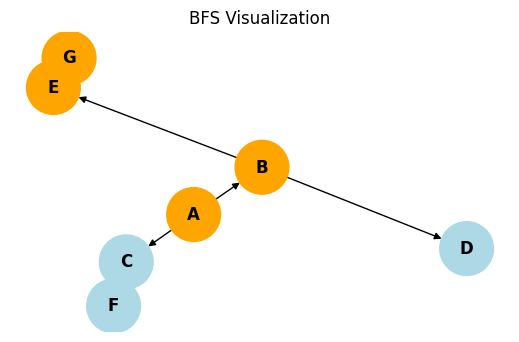

In [ ]:
importimportimportimportimportimportimpoimportimportimportimportimportimportimpoimportimportimportimportimportimportimpoimportimportimportimportimportimportimportimport networkx as nx
import matplotlib.pyplot as plt
from collections import deque

# Graph definition
graph = {
    'A': ['B', 'C'],
    'B': ['D', 'E'],
    'C': ['F'],
    'D': [],
    'E': ['G'],
    'F': [],
    'G': []
}

def bfs(start, goal):
    queue = [[start]]
    visited = []
    while queue:
        path = queue.pop(0)
        node = path[-1]
        if node not in visited:
            visited.append(node)
            if node == goal:
                return path
            for neighbor in graph.get(node, []):
                queue.append(path + [neighbor])
    return None

# Run BFS
path = bfs('A', 'G')
print("BFS Path from A to G:", path)

# Graph Visualization
plt.figure(figsize=(5, 3))
G = nx.DiGraph()
for node, neighbors in graph.items():
    for neighbor in neighbors:
        G.add_edge(node, neighbor)
pos = nx.spring_layout(G)
node_colors = ['orange' if path and node in path else 'lightblue' for node in G.nodes()]
nx.draw(G, pos, with_labels=True, node_color=node_colors, node_size=1500, font_size=12, font_weight='bold', arrows=True)
plt.title("BFS Visualization")
plt.show()

DFS Path from A to G: ['A', 'B', 'E', 'G']


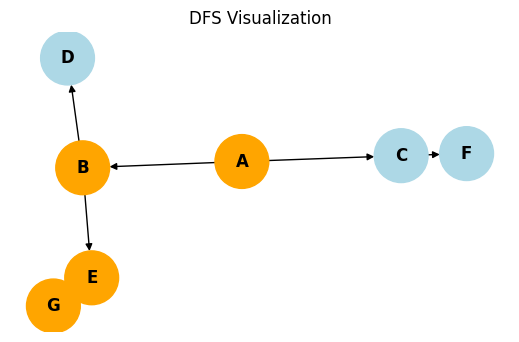

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

# Graph definition
graph = {
    'A': ['B', 'C'],
    'B': ['D', 'E'],
    'C': ['F'],
    'D': [],
    'E': ['G'],
    'F': [],
    'G': []
}

def dfs(start, goal):
    stack = [[start]]
    visited = []
    while stack:
        path = stack.pop()
        node = path[-1]
        if node not in visited:
            visited.append(node)
            if node == goal:
                return path
            for neighbor in reversed(graph.get(node, [])):
                stack.append(path + [neighbor])
    return None

# Run DFS
path = dfs('A', 'G')
print("DFS Path from A to G:", path)

# Graph Visualization
plt.figure(figsize=(5, 3))
G = nx.DiGraph()
for node, neighbors in graph.items():
    for neighbor in neighbors:
        G.add_edge(node, neighbor)
pos = nx.spring_layout(G)
node_colors = ['orange' if path and node in path else 'lightblue' for node in G.nodes()]
nx.draw(G, pos, with_labels=True, node_color=node_colors, node_size=1500, font_size=12, font_weight='bold', arrows=True)
plt.title("DFS Visualization")
plt.show()

DLS Path (Limit=2): None


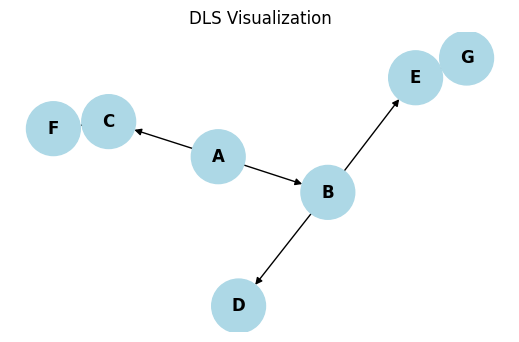

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

# Graph definition
graph = {
    'A': ['B', 'C'],
    'B': ['D', 'E'],
    'C': ['F'],
    'D': [],
    'E': ['G'],
    'F': [],
    'G': []
}

def dls(node, goal, limit, path=[]):
    path = path + [node]
    if node == goal:
        return path
    if limit <= 0:
        return None
    for neighbor in graph.get(node, []):
        if neighbor not in path:
            result = dls(neighbor, goal, limit - 1, path)
            if result is not None:
                return result
    return None

# Run DLS with depth limit = 2
path = dls('A', 'G', limit=2)
print("DLS Path (Limit=2):", path)

# Graph Visualization
plt.figure(figsize=(5, 3))
G = nx.DiGraph()
for node, neighbors in graph.items():
    for neighbor in neighbors:
        G.add_edge(node, neighbor)
pos = nx.spring_layout(G)
node_colors = ['orange' if path and node in path else 'lightblue' for node in G.nodes()]
nx.draw(G, pos, with_labels=True, node_color=node_colors, node_size=1500, font_size=12, font_weight='bold', arrows=True)
plt.title("DLS Visualization")
plt.show()

IDDFS Path from A to G: ['A', 'B', 'E', 'G']


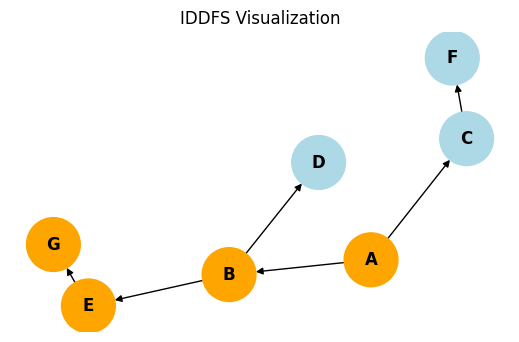

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

# Graph definition
graph = {
    'A': ['B', 'C'],
    'B': ['D', 'E'],
    'C': ['F'],
    'D': [],
    'E': ['G'],
    'F': [],
    'G': []
}

def dls_for_iddfs(node, goal, depth):
    if node == goal:
        return [node]
    if depth <= 0:
        return None
    for neighbor in graph.get(node, []):
        result = dls_for_iddfs(neighbor, goal, depth - 1)
        if result is not None:
            return [node] + result
    return None

def iddfs(start, goal, max_depth):
    for depth in range(max_depth + 1):
        result = dls_for_iddfs(start, goal, depth)
        if result is not None:
            return result
    return None

# Run IDDFS
path = iddfs('A', 'G', max_depth=3)
print("IDDFS Path from A to G:", path)

# Graph Visualization
plt.figure(figsize=(5, 3))
G = nx.DiGraph()
for node, neighbors in graph.items():
    for neighbor in neighbors:
        G.add_edge(node, neighbor)
pos = nx.spring_layout(G)
node_colors = ['orange' if path and node in path else 'lightblue' for node in G.nodes()]
nx.draw(G, pos, with_labels=True, node_color=node_colors, node_size=1500, font_size=12, font_weight='bold', arrows=True)
plt.title("IDDFS Visualization")
plt.show()

UCS Path: ['A', 'B', 'E', 'G'] with Total Cost: 7


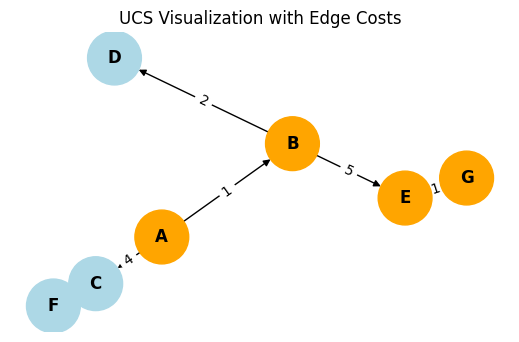

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
import heapq

# Weighted Graph definition for UCS
graph_ucs = {
    'A': {'B': 1, 'C': 4},
    'B': {'D': 2, 'E': 5},
    'C': {'F': 3},
    'D': {},
    'E': {'G': 1},
    'F': {},
    'G': {}
}

def ucs(start, goal):
    queue = [(0, [start])]
    visited = set()
    while queue:
        cost, path = heapq.heappop(queue)
        node = path[-1]
        if node == goal:
            return path, cost
        if node not in visited:
            visited.add(node)
            for neighbor, weight in graph_ucs.get(node, {}).items():
                if neighbor not in visited:
                    heapq.heappush(queue, (cost + weight, path + [neighbor]))
    return None, float('inf')

# Run UCS
path, cost = ucs('A', 'G')
print(f"UCS Path: {path} with Total Cost: {cost}")

# Weighted Graph Visualization
plt.figure(figsize=(5, 3))
G = nx.DiGraph()
for node, neighbors in graph_ucs.items():
    for neighbor, weight in neighbors.items():
        G.add_edge(node, neighbor, weight=weight)
pos = nx.spring_layout(G)
node_colors = ['orange' if path and node in path else 'lightblue' for node in G.nodes()]
nx.draw(G, pos, with_labels=True, node_color=node_colors, node_size=1500, font_size=12, font_weight='bold', arrows=True)
edge_labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)
plt.title("UCS Visualization with Edge Costs")
plt.show()